## Imports

In [6]:
import sys
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from pathlib import Path
import gudhi as gd
from gudhi.representations import PersistenceImage 

# --- BOOTSTRAP & CONFIG ---
cwd = Path.cwd()
root_path = next((p for p in [cwd] + list(cwd.parents) if (p / "config.py").exists()), None)
if root_path and str(root_path) not in sys.path:
    sys.path.insert(0, str(root_path))

import config
config.apply_plot_settings()

BASE_INPUT_DIR = config.RESULTS_DIR / "topo_feats"
BASE_OUTPUT_DIR = config.get_output_dir("persistent_diagrams")
TDA_RES = config.TDA_RES

# 1. Math and TDA Utilities

In [7]:
def make_2d_mask(x: np.ndarray, y: np.ndarray, shape: tuple = (TDA_RES, TDA_RES)) -> np.ndarray:
    """Converts 1D signal to 2D binary mask using fast vectorized NumPy broadcasting."""
    x_norm = np.interp(x, (x.min(), x.max()), (0, shape[1] - 1))
    y_norm = np.interp(y, (y.min(), max(y.max(), 1e-9)), (0, shape[0] - 1))
    
    cols = np.arange(shape[1])
    curve_heights = np.interp(cols, x_norm, y_norm).round().astype(int)
    
    rows = np.arange(shape[0])[:, None] 
    thresholds = shape[0] - 1 - curve_heights
    
    return (rows >= thresholds).astype(np.uint8)

def sweeping_plane_topdown(N):
    """Computes H0 persistence of a binary 2D image."""
    H, W = N.shape
    st = gd.SimplexTree()

    for i in range(H):
        for j in range(W):
            if N[i][j] == 0: continue
            v = i * W + j
            st.insert([v], filtration=i)
            
            if i > 0 and N[i-1][j] == 1:
                st.insert([(i-1)*W + j, v], filtration=i)
            if j > 0 and N[i][j-1] == 1:
                st.insert([i*W + (j-1), v], filtration=i)

    st.set_dimension(2)
    return st.persistence(homology_coeff_field=2), st

def sweeping_plane_direction(N, direction="down"):
    """Helper to adjust direction of sweeping-plane."""
    directions = {
        "down": N,
        "up": np.flipud(N),
        "right": N.T,
        "left": np.flipud(N.T)
    }
    if direction not in directions:
        raise ValueError('direction must be "down", "up", "left", or "right"')
        
    return sweeping_plane_topdown(directions[direction])

# 2. Visualization Utilities

In [9]:
def create_tda_dashboard(cID, input_folder, output_folder, cell_data, feature_types, show=False):
    """Generates and saves the 5x3 GridSpec visualization dashboard."""
    if not cell_data:
        return

    fig = plt.figure(figsize=(16, 20))
    gs = plt.GridSpec(5, 3, figure=fig, width_ratios=[1.2, 1, 1], wspace=0.3, hspace=0.4)

    # --- COLUMN 0: Original Cell Image ---
    ax_orig = fig.add_subplot(gs[:, 0])
    img_path = input_folder / f"cell_{cID}_rotated.png"
    if img_path.exists():
        ax_orig.imshow(mpimg.imread(img_path))
    else:
        ax_orig.text(0.5, 0.5, "Image Not Found", ha='center', va='center')
    ax_orig.set_title(f"Original Cell Image (cID: {cID})", fontsize=14, fontweight='bold')
    ax_orig.axis('off')

    # --- COLUMNS 1 & 2: RDF and ADF features ---
    col_mapping = {"rdf": 1, "adf": 2}
    styles = {'rdf': ('purple', 0.1), 'adf': ('darkorange', 0.2)}

    for feat_type in feature_types:
        if feat_type not in cell_data:
            continue

        col = col_mapping[feat_type]
        data = cell_data[feat_type]
        color, alpha = styles.get(feat_type, ('blue', 0.2))

        # Row 0: 1D Signal
        ax_flat = fig.add_subplot(gs[0, col])
        ax_flat.plot(data['x_vals'], data['y_vals'], color=color, lw=2)
        ax_flat.fill_between(data['x_vals'], data['y_vals'], alpha=alpha, color=color)
        ax_flat.grid(True, alpha=0.3)
        ax_flat.set_title(f"Flattened {feat_type.upper()} Signal")

        # Row 1: 2D Mask
        ax_mask = fig.add_subplot(gs[1, col])
        ax_mask.imshow(data['img_2d'], cmap='binary')
        ax_mask.set_title(f"{feat_type.upper()} 2D Mask")
        ax_mask.axis('off')

        # Rows 2-4: TDA Features
        if data['h0_vals']:
            # Barcode
            ax_bar = fig.add_subplot(gs[2, col])
            gd.plot_persistence_barcode(data['h0_vals'], axes=ax_bar)
            ax_bar.set_title(f"{feat_type.upper()} H0 Barcode")

            # Diagram
            ax_diag = fig.add_subplot(gs[3, col])
            births = [p[1][0] for p in data['h0_vals'] if p[1][1] != float('inf')]
            deaths = [p[1][1] for p in data['h0_vals'] if p[1][1] != float('inf')]
            persistences = [d - b for b, d in zip(births, deaths)]

            ax_diag.scatter(births, persistences, alpha=0.6, color=color, edgecolor='black', lw=0.5)
            ax_diag.axhline(0, color='black', lw=1, zorder=0)
            ax_diag.set_title(f"{feat_type.upper()} H0 Birth-Pers. Diagram")
            ax_diag.grid(True, alpha=0.3)

            # Persistence Image
            if data['p_image_matrix'] is not None:
                ax_pi = fig.add_subplot(gs[4, col])
                cax = ax_pi.imshow(data['p_image_matrix'], cmap='viridis', origin='lower')
                fig.colorbar(cax, ax=ax_pi, fraction=0.046, pad=0.04)
                ax_pi.set_title(f"{feat_type.upper()} H0 Pers. Image")
        else:
            for r in [2, 3, 4]:
                ax_empty = fig.add_subplot(gs[r, col])
                ax_empty.text(0.5, 0.5, "No Features", ha='center', va='center')
                ax_empty.axis('off')

    save_path = output_folder / f"cell_{cID}_TDA_dashboard.png"
    fig.savefig(save_path, dpi=150, bbox_inches='tight')
    if show:
        plt.show()
    plt.close(fig)


# 3. Main Pipeline

Starting TDA pipeline for 399 cells...


/Users/ploypusee/Library/CloudStorage/GoogleDrive-ploy.polyluna@gmail.com/My Drive/2 Work/Research/01 Active Project/TDA Cell Classification/.venv/lib/python3.9/site-packages/gudhi/persistence_graphical_tools.py:129: UserWarning: usetex mode requires TeX.
  warnings.warn("usetex mode requires TeX.")


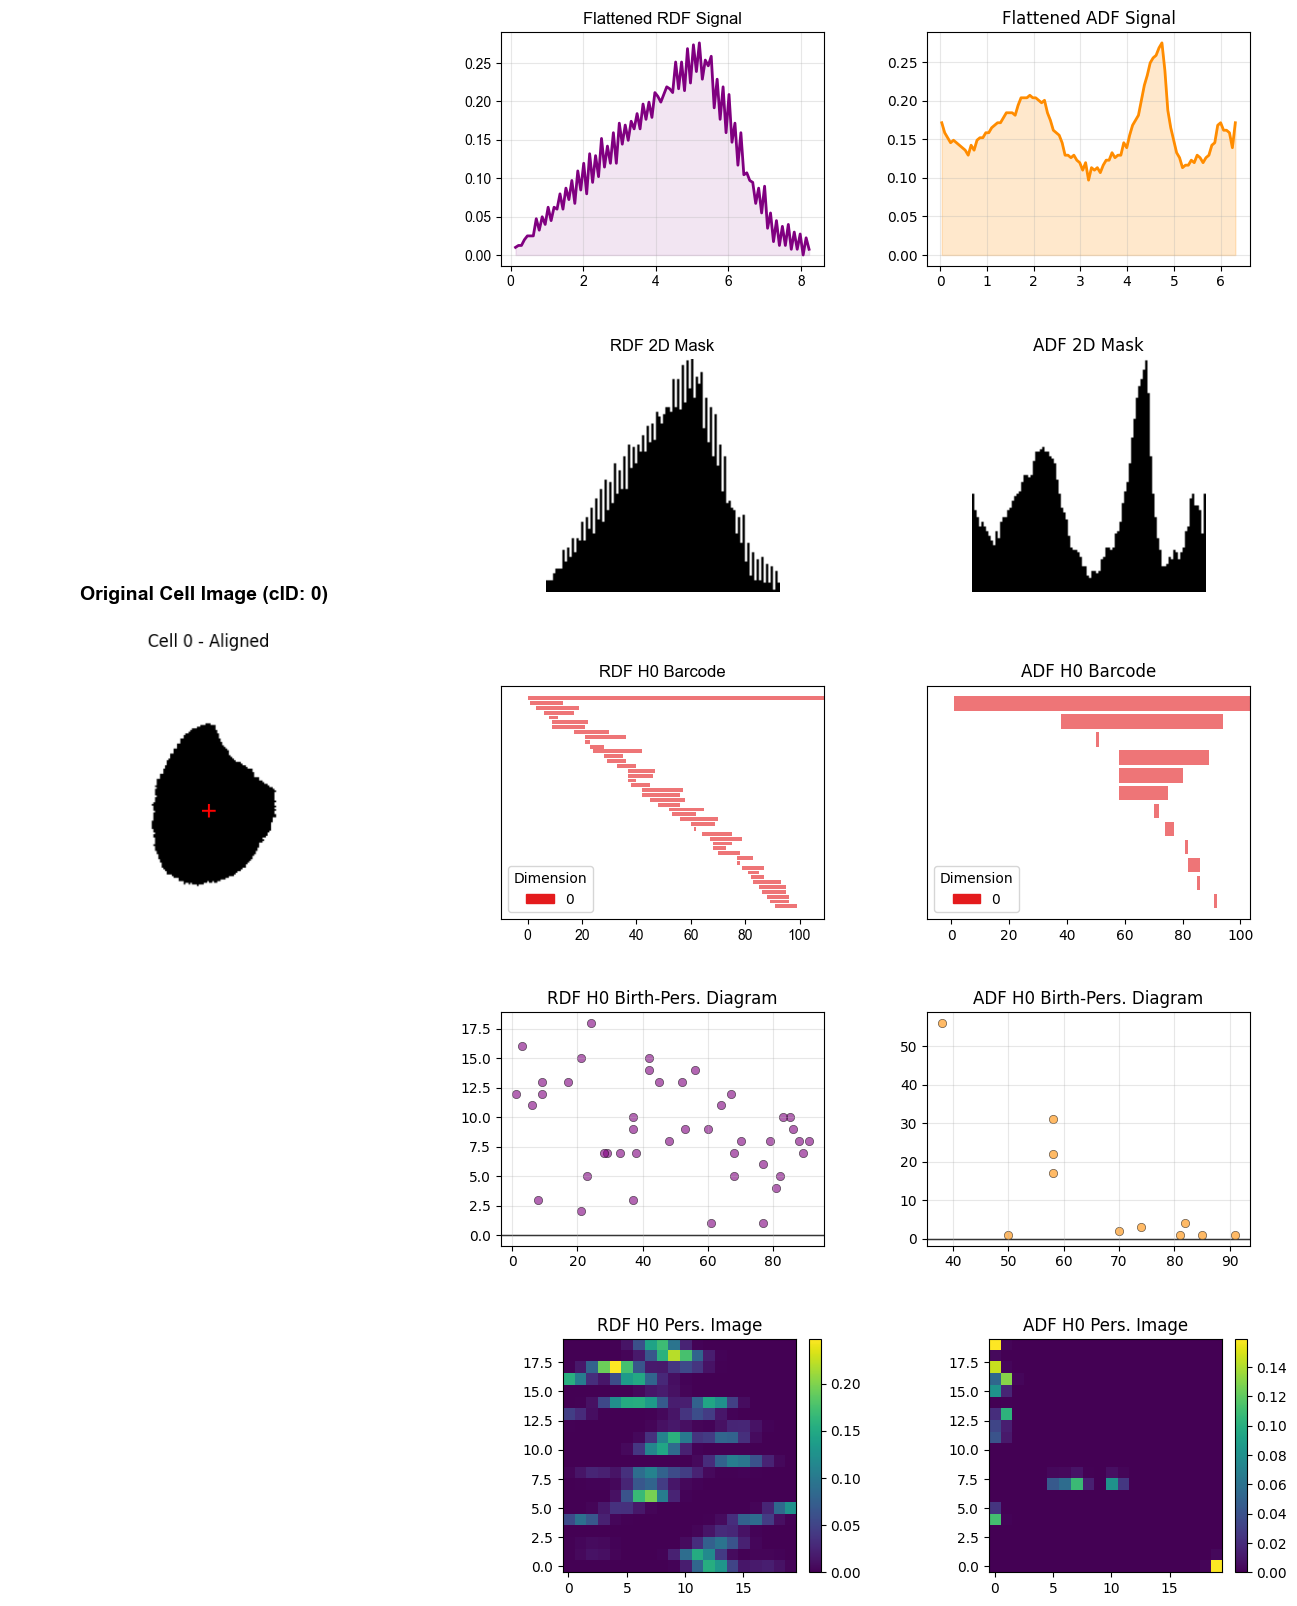

Processed and visualized Cell 0


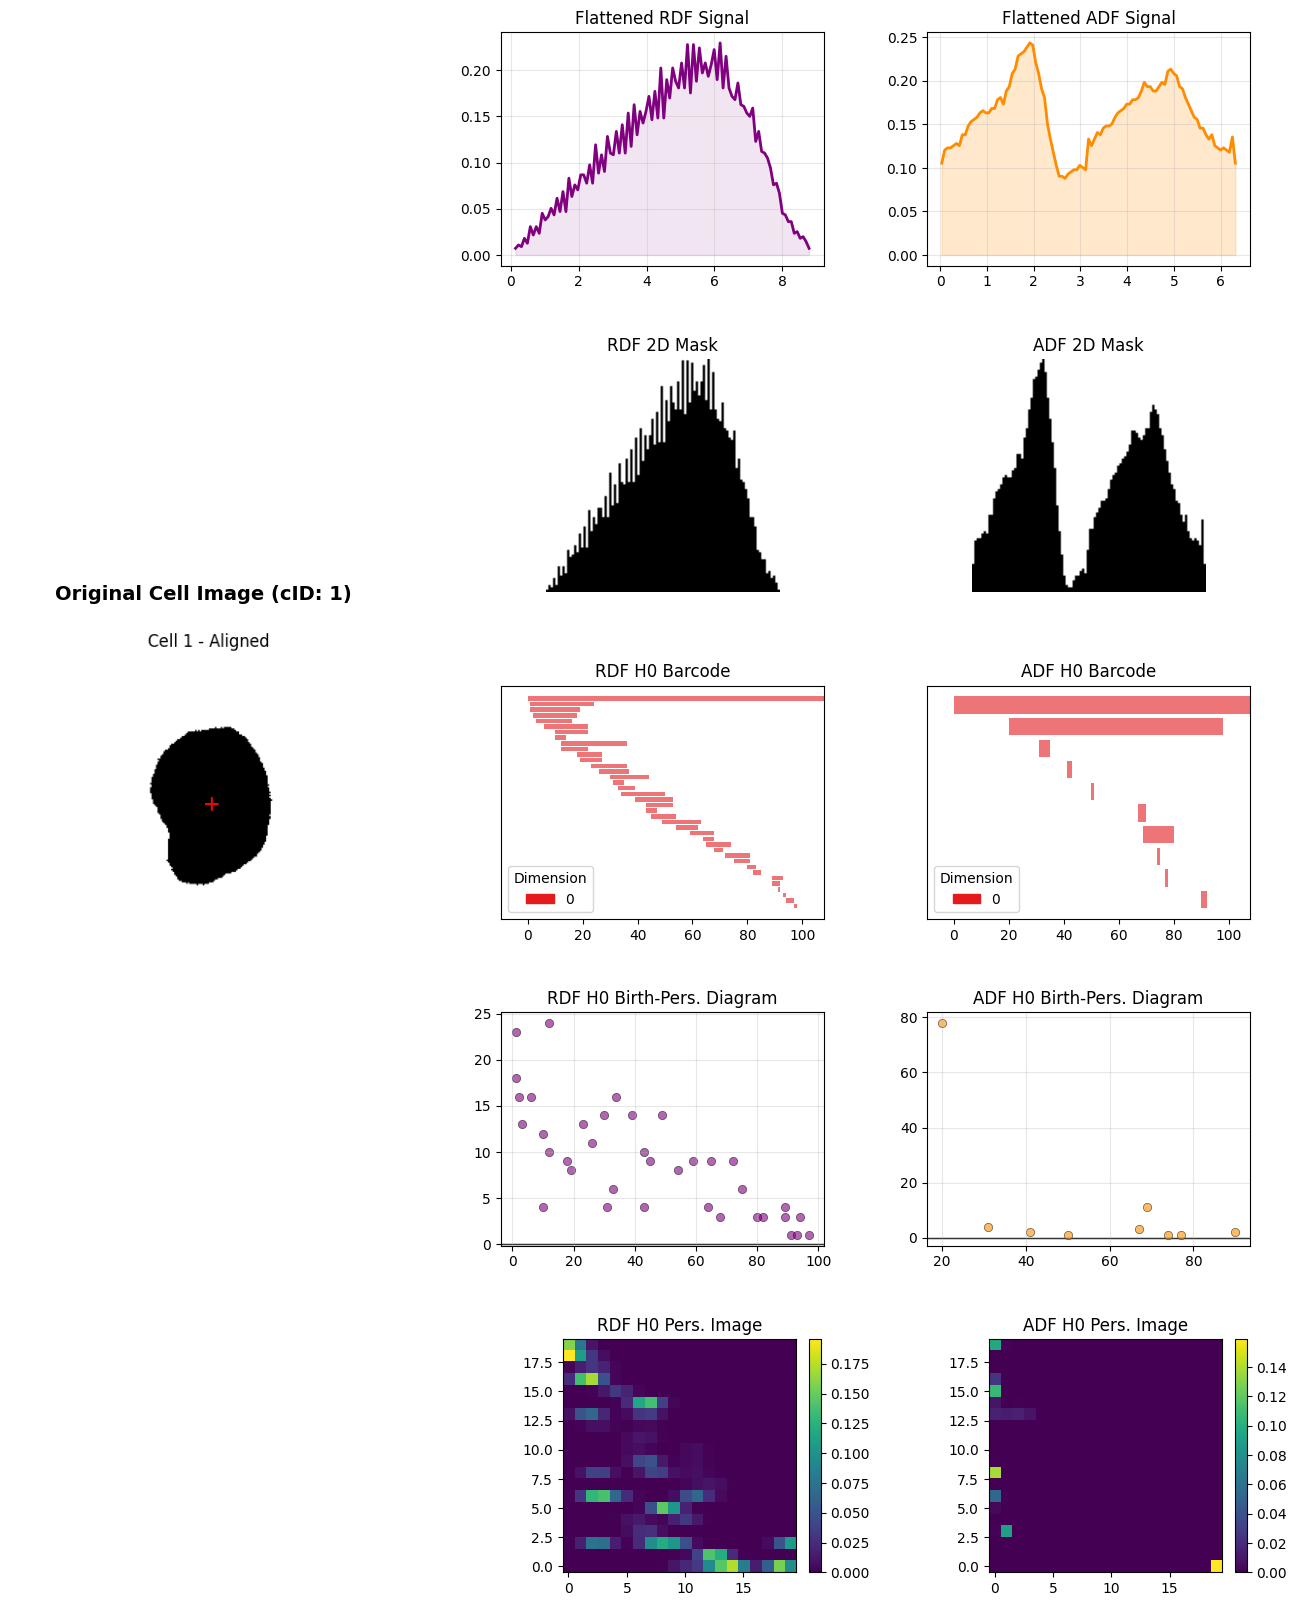

Processed and visualized Cell 1


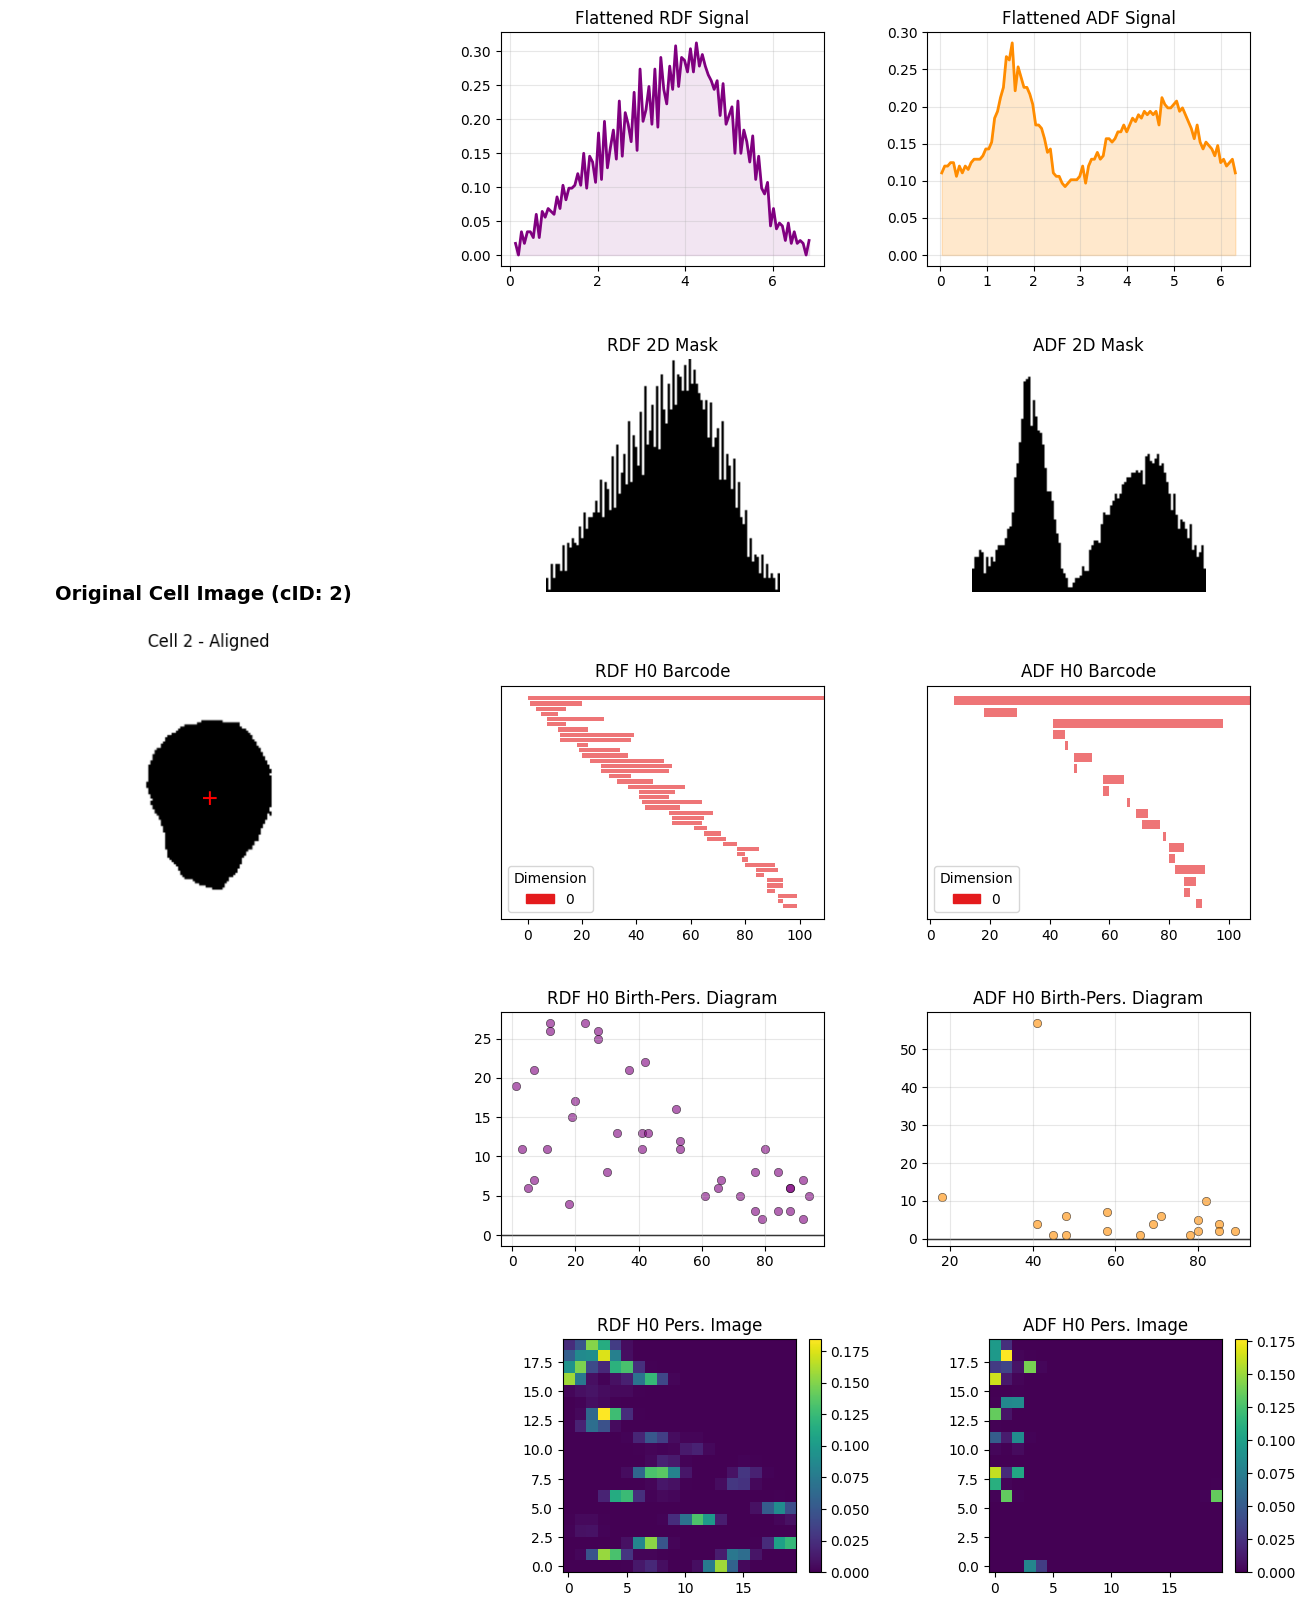

Processed and visualized Cell 2


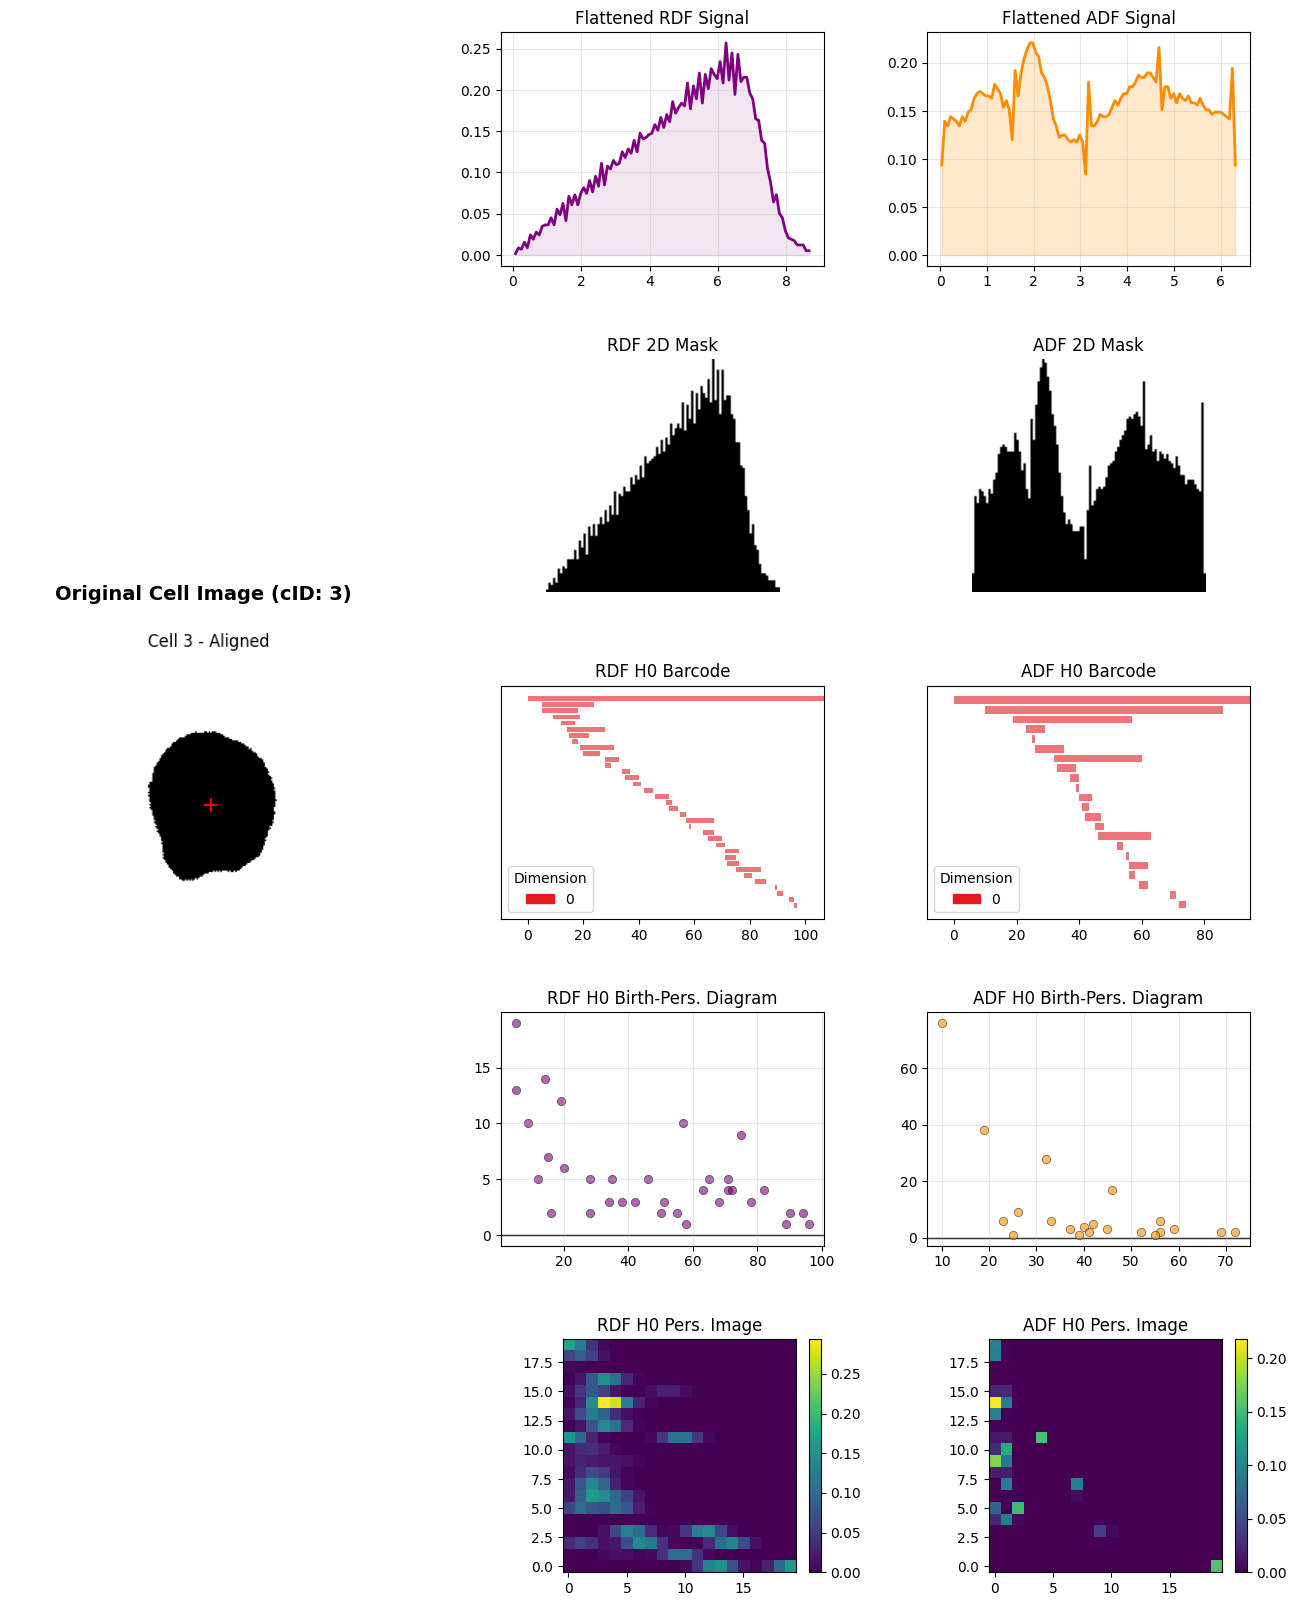

Processed and visualized Cell 3


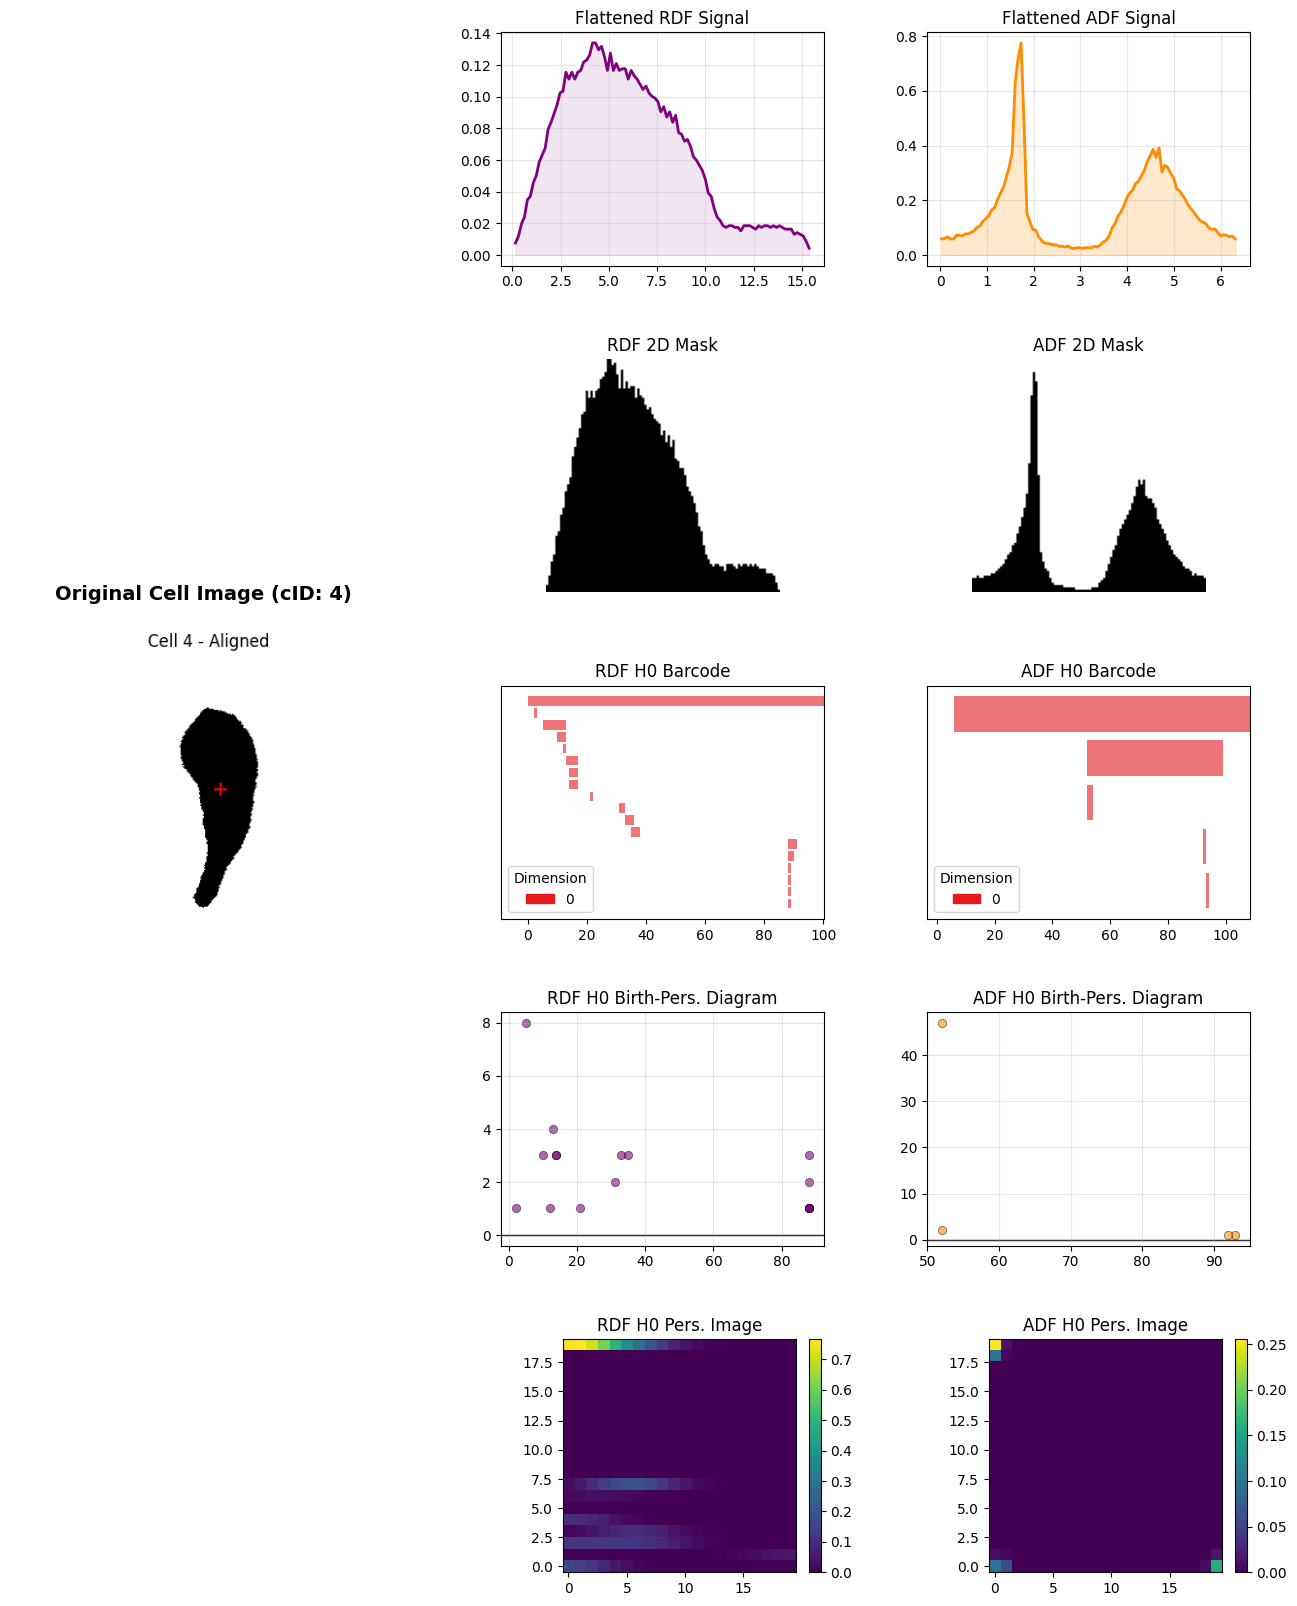

Processed and visualized Cell 4


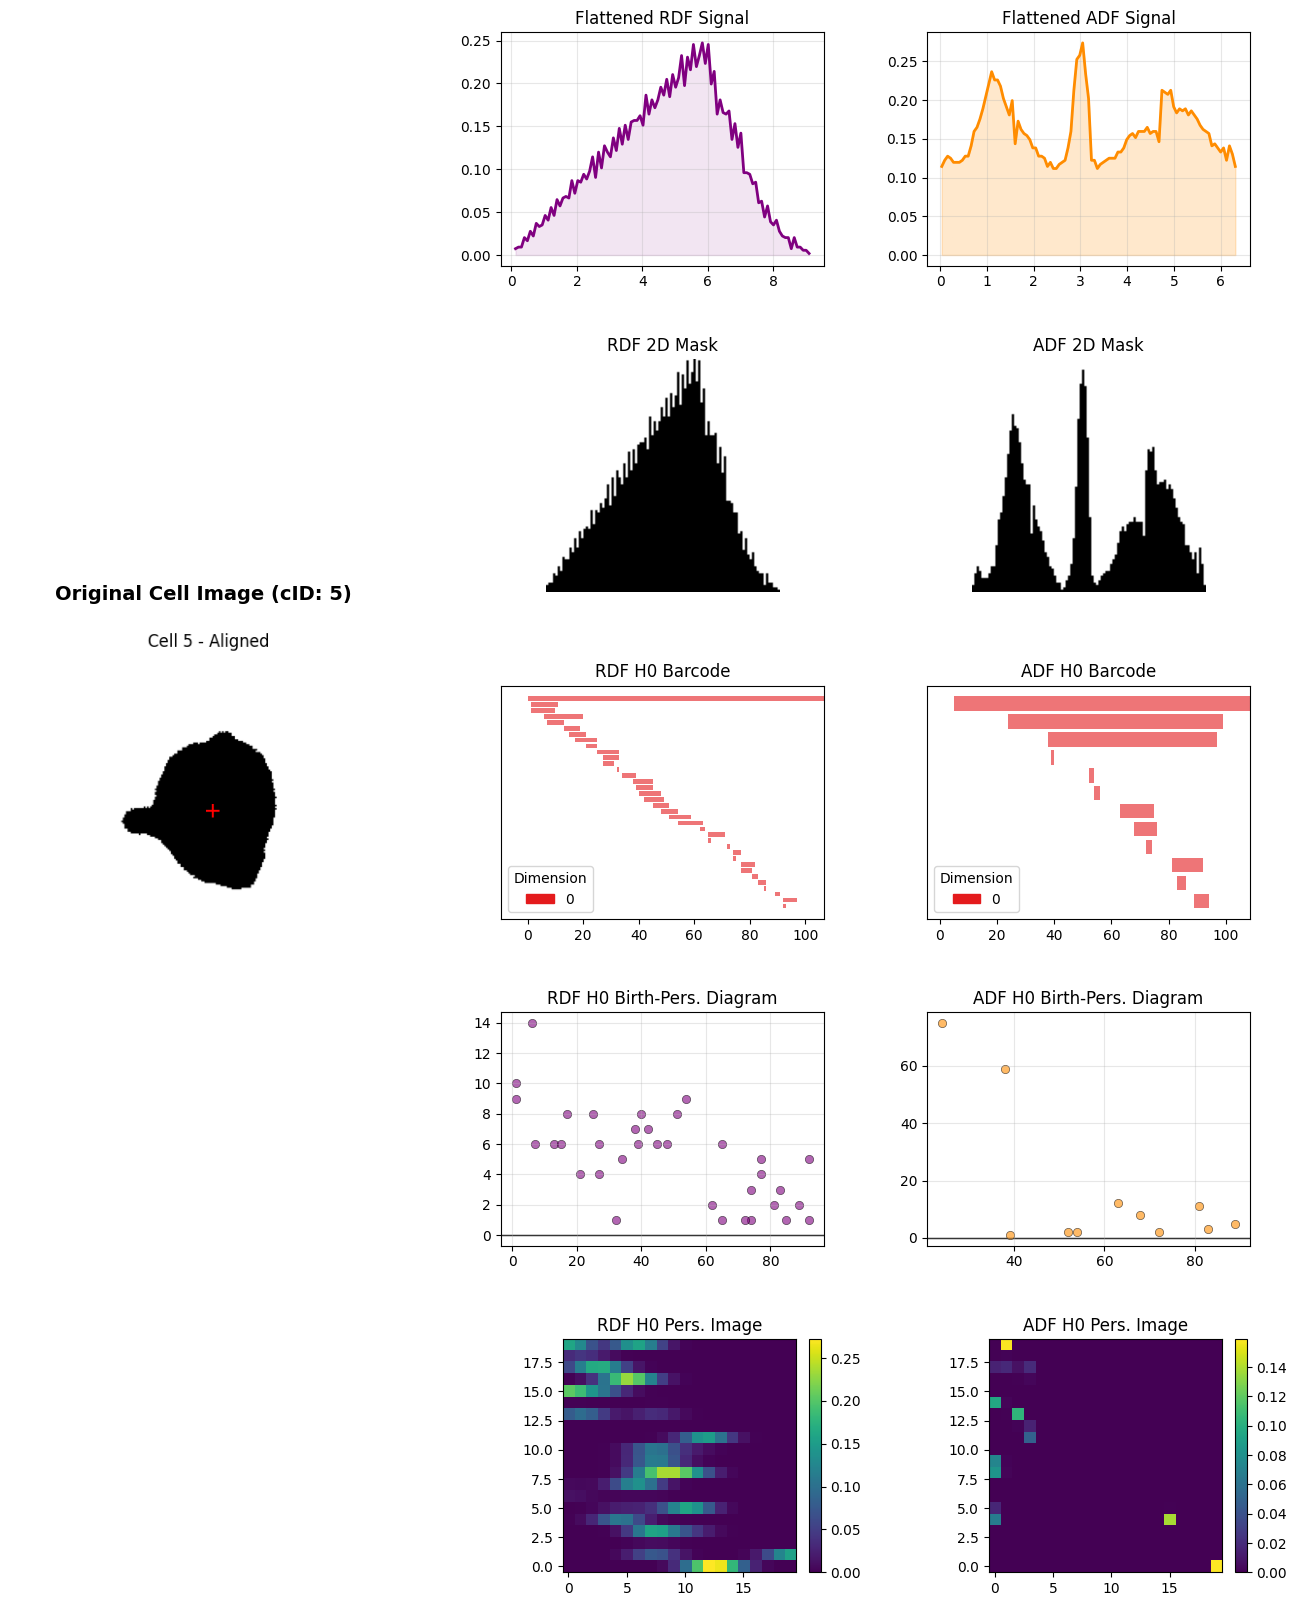

Processed and visualized Cell 5


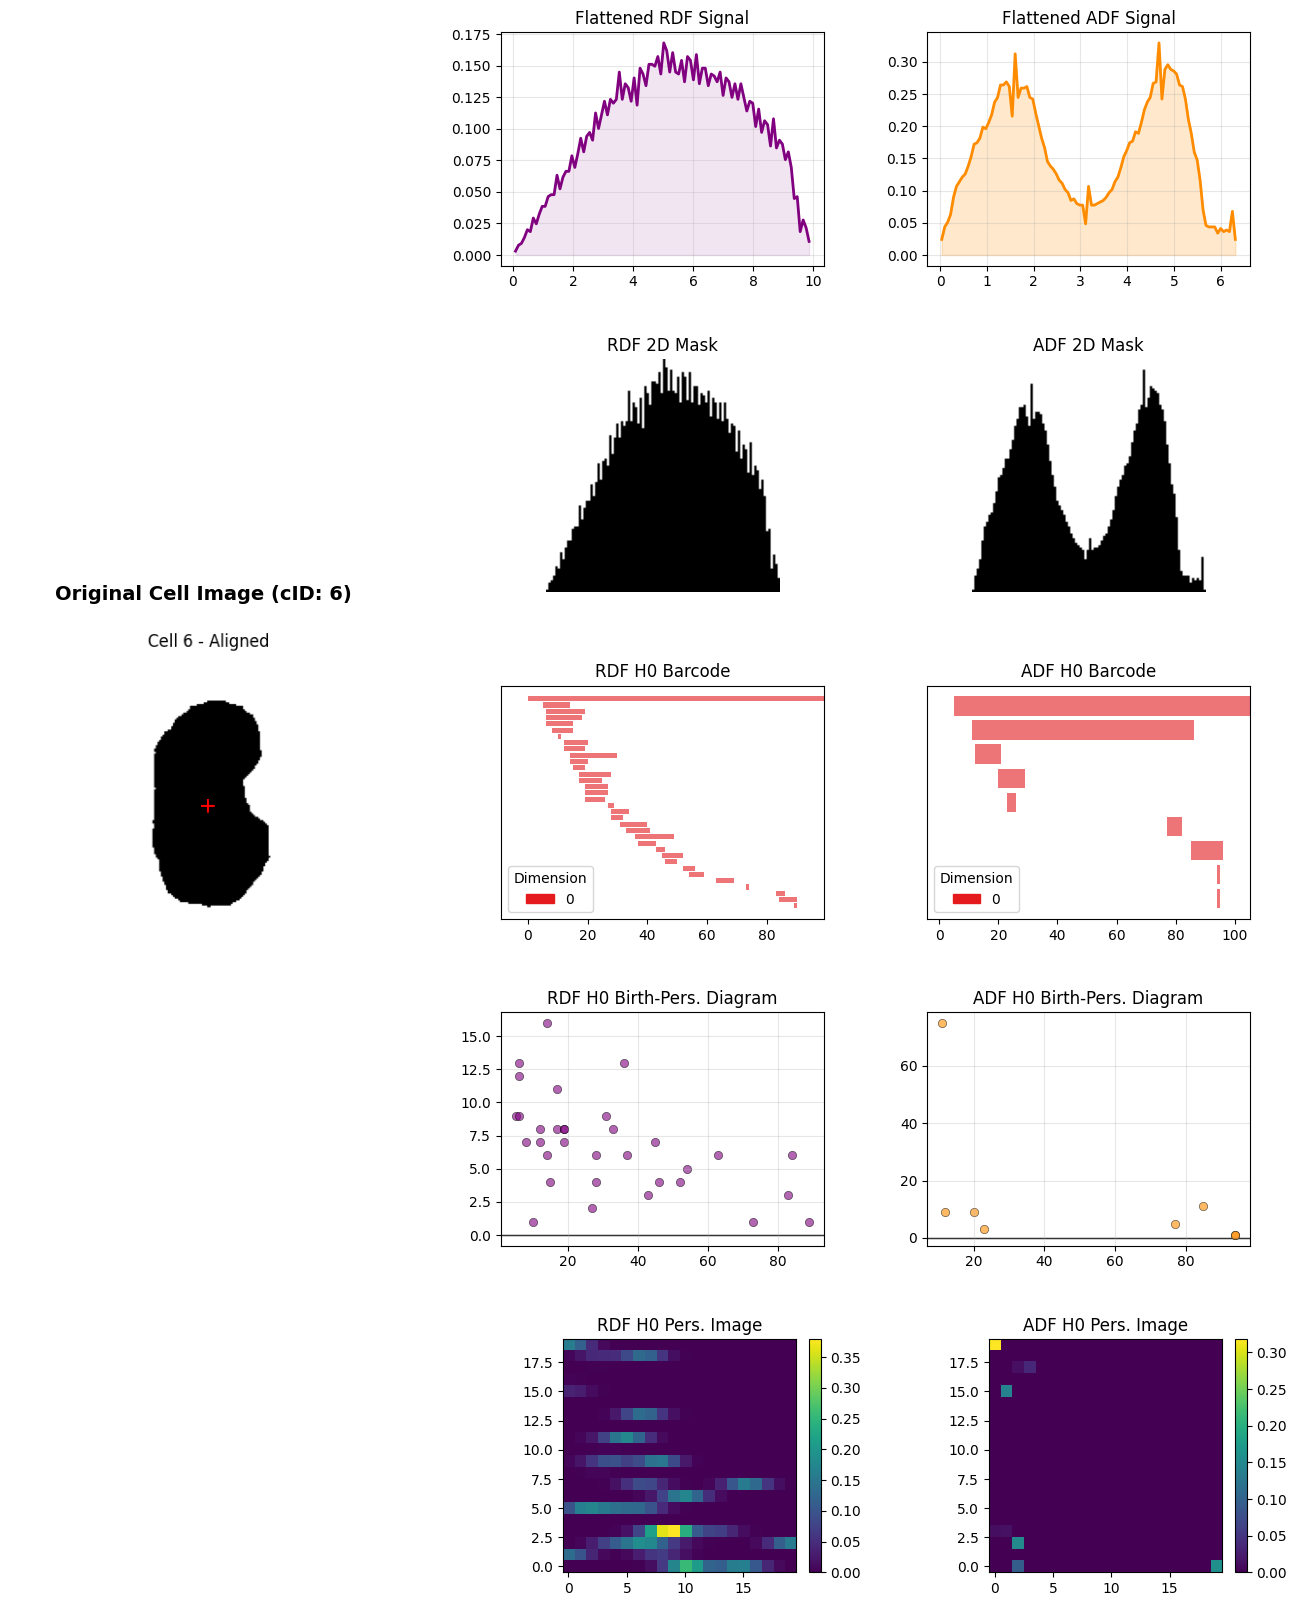

Processed and visualized Cell 6


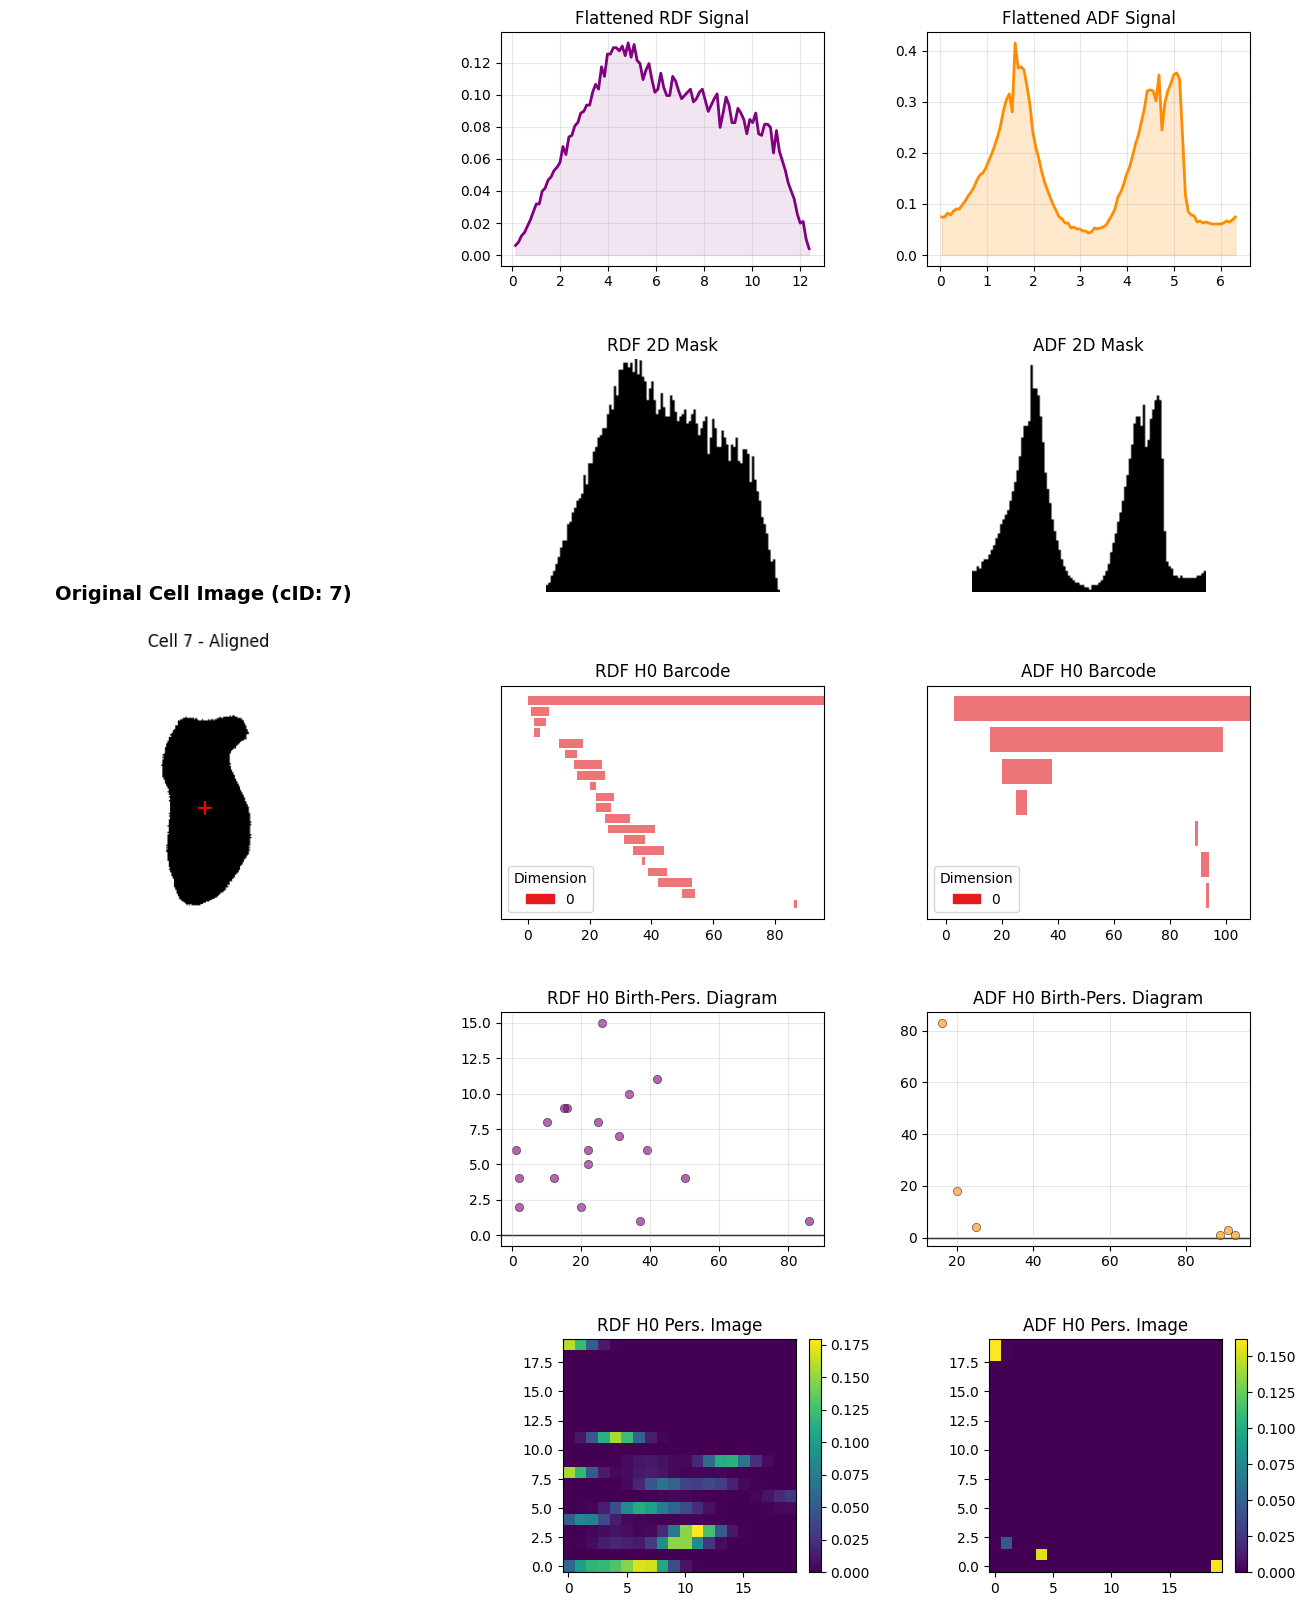

Processed and visualized Cell 7


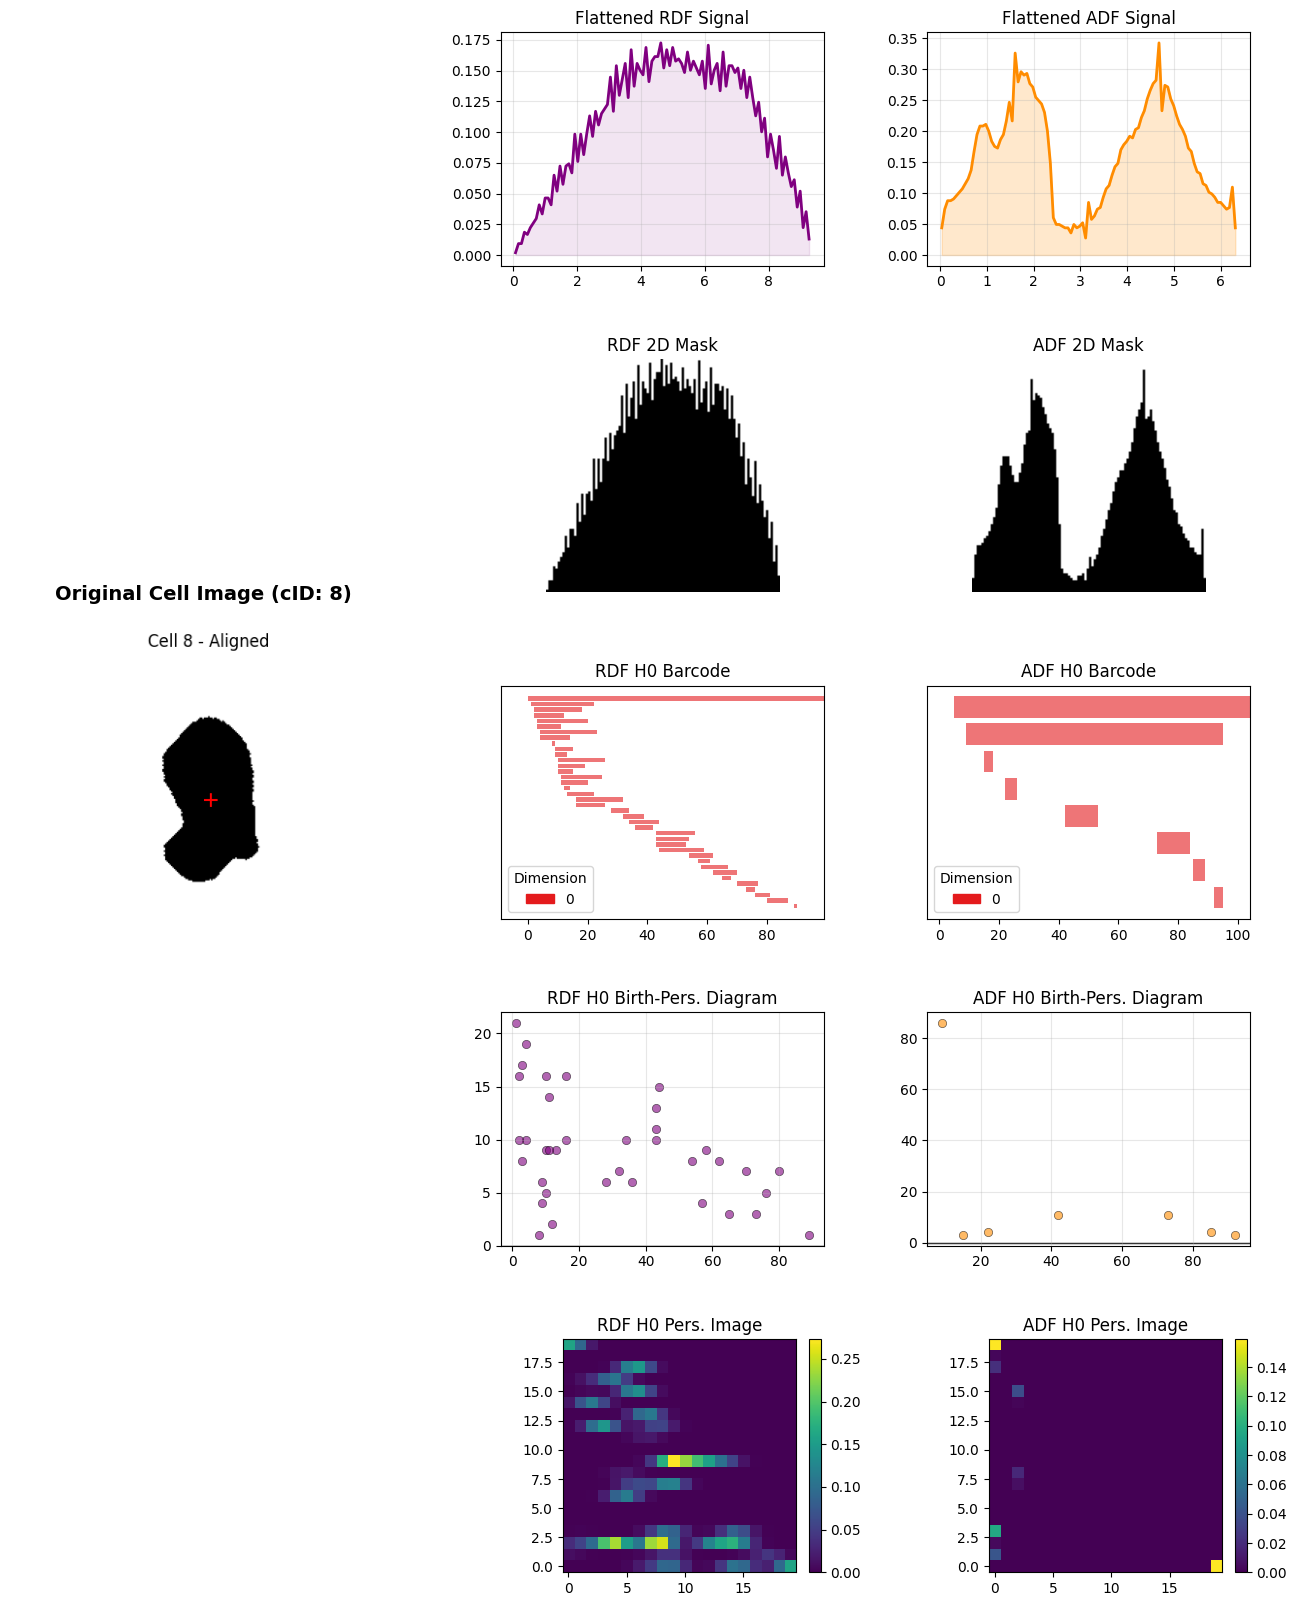

Processed and visualized Cell 8


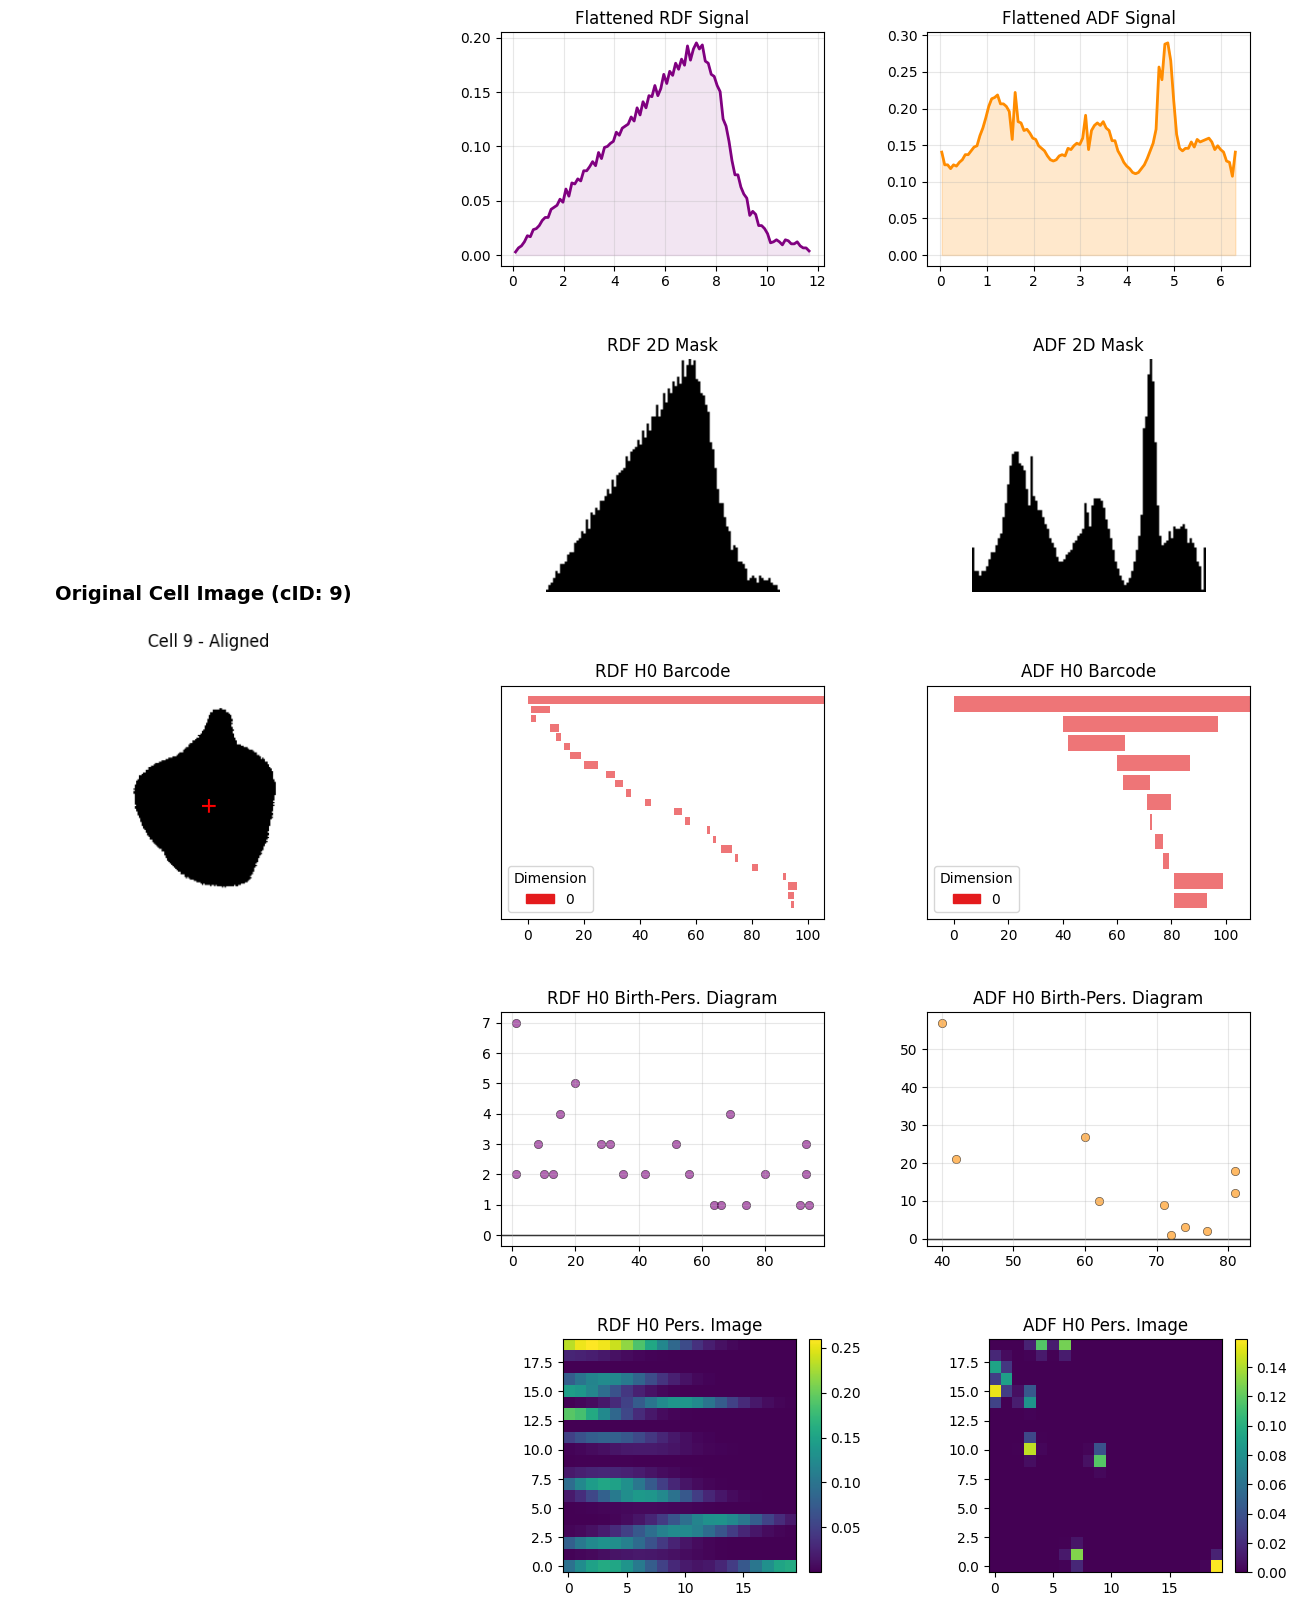

Processed and visualized Cell 9
Processed Cell 10 (Visualization skipped)
Processed Cell 11 (Visualization skipped)
Processed Cell 12 (Visualization skipped)
Processed Cell 13 (Visualization skipped)
Processed Cell 14 (Visualization skipped)
Processed Cell 15 (Visualization skipped)
Processed Cell 16 (Visualization skipped)
Processed Cell 17 (Visualization skipped)
Processed Cell 18 (Visualization skipped)
Processed Cell 19 (Visualization skipped)
Processed Cell 20 (Visualization skipped)
Processed Cell 21 (Visualization skipped)
Processed Cell 22 (Visualization skipped)
Processed Cell 23 (Visualization skipped)
Processed Cell 24 (Visualization skipped)
Processed Cell 25 (Visualization skipped)
Processed Cell 26 (Visualization skipped)
Processed Cell 27 (Visualization skipped)
Processed Cell 28 (Visualization skipped)
Processed Cell 29 (Visualization skipped)
Processed Cell 30 (Visualization skipped)
Processed Cell 31 (Visualization skipped)
Processed Cell 32 (Visualization skipped)
Pr

In [10]:
NUM_TO_PROCESS = 399
VISUALIZE_LIMIT = 10  
FEATURE_TYPES = ["rdf", "adf"] 

pi_transformer = PersistenceImage(bandwidth=1.0, resolution=[20, 20])
print(f"Starting TDA pipeline for {NUM_TO_PROCESS} cells...")

for cID in range(NUM_TO_PROCESS):
    input_folder = BASE_INPUT_DIR / f"cID_{cID}"
    output_folder = BASE_OUTPUT_DIR / f"cID_{cID}"
    output_folder.mkdir(parents=True, exist_ok=True)
    
    cell_data = {}
    
    # 1. CRUNCH THE MATH
    for feat_type in FEATURE_TYPES:
        data_file = input_folder / f"cell_{cID}_{feat_type}_raw.npy"
        if not data_file.exists(): continue
            
        x_vals, y_vals = np.load(data_file)
        img_2d = make_2d_mask(x_vals, y_vals)
        persistence_vals, _ = sweeping_plane_direction(img_2d, direction="down")
        
        h0_vals = [p for p in persistence_vals if p[0] == 0]
        intervals = [p[1] for p in h0_vals if p[1][1] != float('inf')] 
        
        p_image_matrix = None
        if intervals:
            p_image_matrix = pi_transformer.fit_transform([np.array(intervals)])[0].reshape(20, 20).T
            np.save(output_folder / f"cell_{cID}_{feat_type}_pimage.npy", p_image_matrix)
        
        cell_data[feat_type] = {
            'x_vals': x_vals, 'y_vals': y_vals, 'img_2d': img_2d, 
            'h0_vals': h0_vals, 'p_image_matrix': p_image_matrix
        }

    # 2. GENERATE THE DASHBOARD
    if cID < VISUALIZE_LIMIT:
        create_tda_dashboard(cID, input_folder, output_folder, cell_data, FEATURE_TYPES, show=True)
        print(f"Processed and visualized Cell {cID}")
    else:
        print(f"Processed Cell {cID} (Visualization skipped)")

print("--- TDA Pipeline Complete! ---")